# Student Performance Analytics Engine

This project analyzes made-up marks for 500 students across 6 subjects. It calculates subject and student results, ranks students, and looks for unusually high or low marks.

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

np.random.seed(7)

**Create sample marks.**

In [19]:
marks = np.random.normal(65, 12, (500, 6))
marks = np.clip(marks, 0, 100)

subjects = ["Math", "Science", "English", "History", "Computer", "Art"]

first_names = [
    "Sara",
    "Athravv", "Gaurav", "Sahil", "Saksham", "Sneha",
    "Santoshi", "Kashish", "Shubham", "Rudra", "Mahi",
    "Amruta"
]

name_rng = np.random.default_rng(7)
students = [
    f"{name_rng.choice(first_names)} {i}"
    for i in range(1, 501)
]

marks_table = pd.DataFrame(marks, columns=subjects, index=students)

display(marks_table.head(10))

,Math,Science,English,History,Computer,Art
Amruta 1,85.286308,59.408752,65.393842,69.890195,55.532924,65.024787
Kashish 2,64.989315,43.943308,77.211896,72.205982,57.494852,62.941421
Shubham 3,71.063592,61.863723,62.087011,47.561103,71.654964,66.486571
Mahi 4,68.293519,46.681706,84.808396,66.852026,60.354321,89.348867
Santoshi 5,64.455368,47.591856,60.137266,37.540219,77.592759,60.002308
Rudra 6,56.089358,77.869642,45.187093,71.425152,40.227022,57.054088
Mahi 7,50.549362,82.543708,86.193931,61.047035,75.088799,62.840163
Gaurav 8,71.816743,55.965954,44.499930,43.362816,69.597462,91.971141
Sara 9,68.232940,58.704745,87.944226,67.847622,66.217208,68.030933
Sahil 10,63.411474,61.286284,47.780438,71.019489,63.862695,79.317031


**Calculate each subjects results**

In [20]:
subject_results = pd.DataFrame({
    "Average": marks_table.mean(),
    "Median": marks_table.median(),
    "Highest mark": marks_table.max(),
    "Lowest mark": marks_table.min()
})

display(subject_results.round(2))

,Average,Median,Highest mark,Lowest mark
Math,65.00,64.54,100.00,28.01
Science,64.04,65.15,93.22,26.53
English,65.27,64.40,100.00,29.10
History,65.98,66.29,96.65,36.04
Computer,64.53,64.39,100.00,30.11
Art,63.67,64.35,100.00,25.93


**Find the top-performing studentstext**

In [21]:
student_results = pd.DataFrame({
    "Average mark": marks_table.mean(axis=1),
    "Total marks": marks_table.sum(axis=1)
})

student_results["Rank"] = student_results["Average mark"].rank(
    ascending=False,
    method="min"
).astype(int)

student_results = student_results.sort_values("Rank")

display(student_results.head(10).round(2))

,Average mark,Total marks,Rank
Gaurav 407,78.53,471.21,1
Kashish 244,77.64,465.86,2
Gaurav 95,77.16,462.96,3
Gaurav 165,76.34,458.07,4
Saksham 345,76.09,456.56,5
Saksham 102,75.55,453.29,6
Santoshi 98,74.96,449.76,7
Athravv 426,74.39,446.35,8
Sara 420,74.35,446.11,9
Amruta 265,74.33,445.97,10


**Find unusually high or low marks**

In [22]:
z_scores = (marks_table - marks_table.mean()) / marks_table.std()

outlier_counts = (z_scores.abs() > 2).sum()

print("Unusually high or low marks in each subject:")
display(outlier_counts.to_frame("Number of unusual marks"))

Unusually high or low marks in each subject:


,Number of unusual marks
Math,23
Science,20
English,21
History,23
Computer,27
Art,20


**Chart of the subject averages**

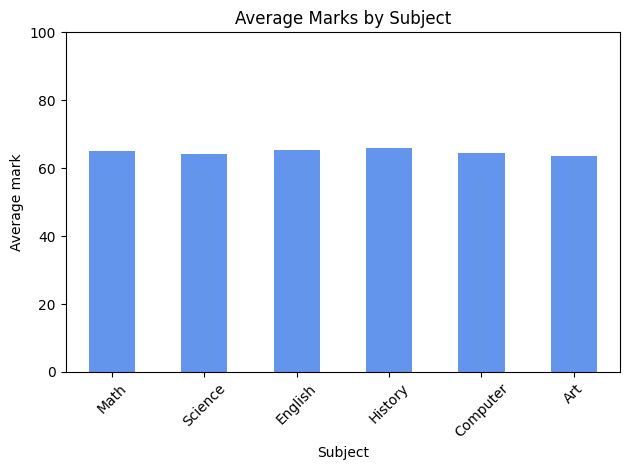

In [23]:
subject_results["Average"].plot(kind="bar", color="cornflowerblue")

plt.title("Average Marks by Subject")
plt.xlabel("Subject")
plt.ylabel("Average mark")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Top 10 students**

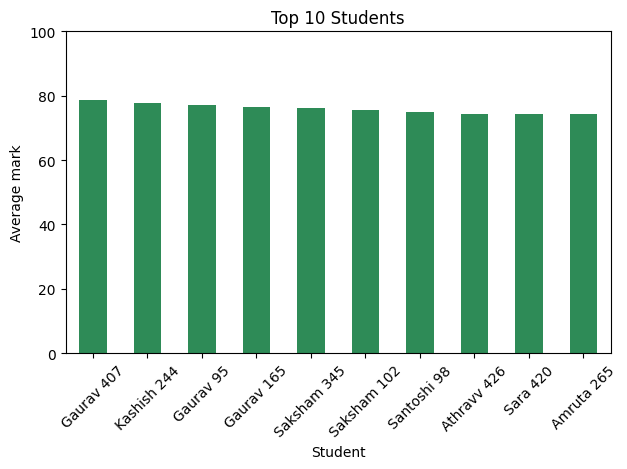

In [24]:
top_students = student_results.head(10)

top_students["Average mark"].plot(kind="bar", color="seagreen")

plt.title("Top 10 Students")
plt.xlabel("Student")
plt.ylabel("Average mark")
plt.ylim(0, 100)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()